In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(ROOT / "data" / "processed" / "daily.parquet")
print(df.shape, df.index.min().date(), "→", df.index.max().date())
print("Missing demand days:", df["demand_mw"].isna().sum(), "| imputed:", df["imputed"].sum())

# Did the day/month order parse correctly?
print("Days in February:", df[df.index.month == 2].groupby(df[df.index.month == 2].index.year).size().to_dict())
print("Mean demand Jan vs Jul (MW):", round(df[df.index.month == 1]["demand_mw"].mean()),
      "vs", round(df[df.index.month == 7]["demand_mw"].mean()))
df.head()

(1826, 6) 2019-01-01 → 2023-12-31
Missing demand days: 1 | imputed: 3
Days in February: {2019: 28, 2020: 29, 2021: 28, 2022: 28, 2023: 28}
Mean demand Jan vs Jul (MW): 29222 vs 17605


,demand_mw,peak_mw,temp_mean,temp_max,temp_min,imputed
date,,,,,,
2019-01-01,24825.163333,27202.24,-3.61,1.77,-14.20,0
2019-01-02,29574.361667,32688.48,-14.89,-11.61,-18.97,0
2019-01-03,29974.362500,31878.35,-9.14,-3.39,-13.95,0
2019-01-04,26162.870833,27656.98,-0.33,2.56,-5.12,0
2019-01-05,23386.398750,25361.76,-1.10,2.02,-5.45,0


C:\Users\fatim\AppData\Local\Temp\ipykernel_29200\251182533.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  weekend = d.index.dayofweek >= 5


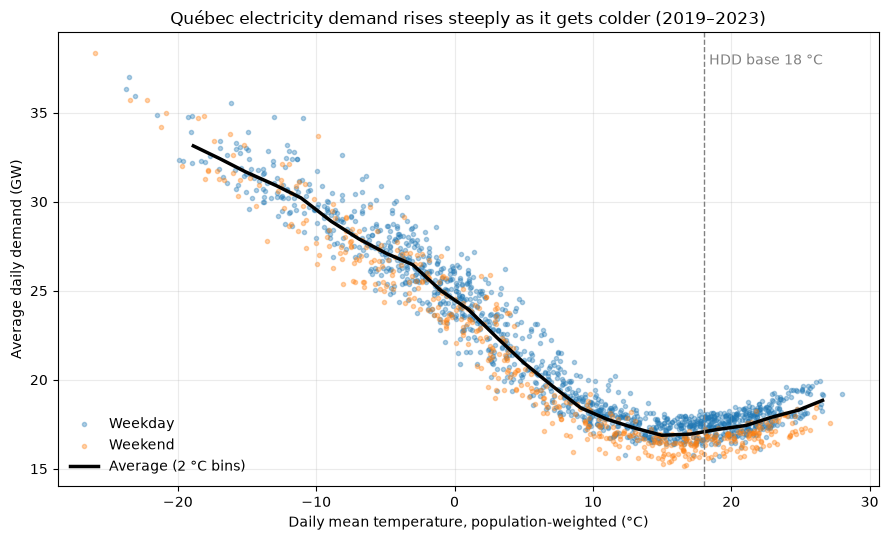

In [2]:
d = df.dropna(subset=["demand_mw", "temp_mean"]).copy()
d["gw"] = d["demand_mw"] / 1000
weekend = d.index.dayofweek >= 5

# average demand per 2 °C bin: the curve the eye should follow
bins = np.arange(np.floor(d["temp_mean"].min()), d["temp_mean"].max() + 2, 2)
d["tbin"] = pd.cut(d["temp_mean"], bins)
curve = d.groupby("tbin", observed=True).agg(t=("temp_mean", "mean"), gw=("gw", "mean"), n=("gw", "size"))
curve = curve[curve["n"] >= 10]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(d.loc[~weekend, "temp_mean"], d.loc[~weekend, "gw"], s=9, alpha=.35, label="Weekday")
ax.scatter(d.loc[weekend, "temp_mean"], d.loc[weekend, "gw"], s=9, alpha=.35, label="Weekend")
ax.plot(curve["t"], curve["gw"], color="black", lw=2.5, label="Average (2 °C bins)")
ax.axvline(18, ls="--", color="grey", lw=1)
ax.text(18.4, ax.get_ylim()[1] * .97, "HDD base 18 °C", va="top", color="grey")

ax.set_xlabel("Daily mean temperature, population-weighted (°C)")
ax.set_ylabel("Average daily demand (GW)")
ax.set_title("Québec electricity demand rises steeply as it gets colder (2019–2023)")
ax.legend(frameon=False)
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(FIG / "eda_demand_vs_temperature.png", dpi=150)
plt.show()

In [4]:
cold = d[d["temp_mean"] < 10]
slope, intercept = np.polyfit(cold["temp_mean"], cold["demand_mw"], 1)
print(f"Below 10 °C, each degree colder adds about {-slope:,.0f} MW of demand")

flat = d[d["temp_mean"].between(15, 20)]["demand_mw"]
print(f"Between 15 and 20 °C demand is flattest: {flat.mean():,.0f} MW on average")

kink = curve.loc[curve["gw"].idxmin(), "t"]
print(f"Lowest average demand around {kink:.0f} °C  →  natural HDD base candidate")

print(df[["demand_mw", "temp_mean"]].nlargest(5, "demand_mw"))

Below 10 °C, each degree colder adds about 552 MW of demand
Between 15 and 20 °C demand is flattest: 17,029 MW on average
Lowest average demand around 15 °C  →  natural HDD base candidate
               demand_mw  temp_mean
date                               
2023-02-04  38353.170000     -25.99
2023-02-03  37009.477500     -23.55
2022-01-11  36335.880417     -23.74
2022-01-21  35921.840417     -23.11
2022-01-15  35714.321250     -23.49


### Demand vs temperature: what the data shows

- **Heating drives demand:** Below 10 °C, each degree colder adds about **552 MW** of average daily demand. Daily demand roughly doubles between mild days (~17 GW at 15 °C) and the coldest days (~33 GW at −19 °C), because most Québec buildings heat with electricity.
- **The comfort zone sits lower than the textbook 18 °C:** Demand is flattest between 15 and 20 °C (~17,000 MW on average) and lowest around **15 °C**. Heating starts below ~15 °C, which suggests an HDD base of 15 °C rather than the conventional 18 °C. To test in the backtest (S3, experiment 1).
- **Cooling exists but is small:** Above ~20 °C demand rises again, from ~17 to ~19 GW at 26 °C, roughly a quarter of the heating slope. CDD is kept as a feature, but heating dominates.
- **Weekends are lower at the same temperature:** Weekend points sit consistently below weekday points (roughly 1 GW), as businesses and industry use less. Calendar features (weekday, weekend, holidays) are needed on top of weather.
- **The slope eases in extreme cold:** Between 10 °C and −10 °C the curve rises ~0.6 GW per degree, but only ~0.35 GW per degree below −10 °C. There are few such days, so this is uncertain, but a single linear HDD term may slightly over-predict the coldest days. Tree models (LightGBM) can capture this bend; worth checking errors on the coldest days in the backtest.
- **Temperature does not explain everything:** At a given temperature demand still varies by 3–4 GW: weekday, holidays, wind and cloud, the 2020 COVID period, and recent demand. This is why the model also uses lagged demand and calendar features.
- **Extreme days matter most:** The five highest-demand days in 2019–2023 were all below −23 °C: the **3–4 February 2023 cold snap** (38.4 GW on 4 February at −26 °C, the highest in the data) and three days in **January 2022**. These rare days are what the grid operator plans for, and the hardest to forecast, because there are few examples of them in the training data.

**Feature decisions from this plot:** HDD (and test a 15 °C base), CDD, weekend/weekday and holiday flags, and lagged demand to capture what weather alone does not.

C:\Users\fatim\AppData\Local\Temp\ipykernel_29200\3148335809.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  d["dow"] = d.index.dayofweek


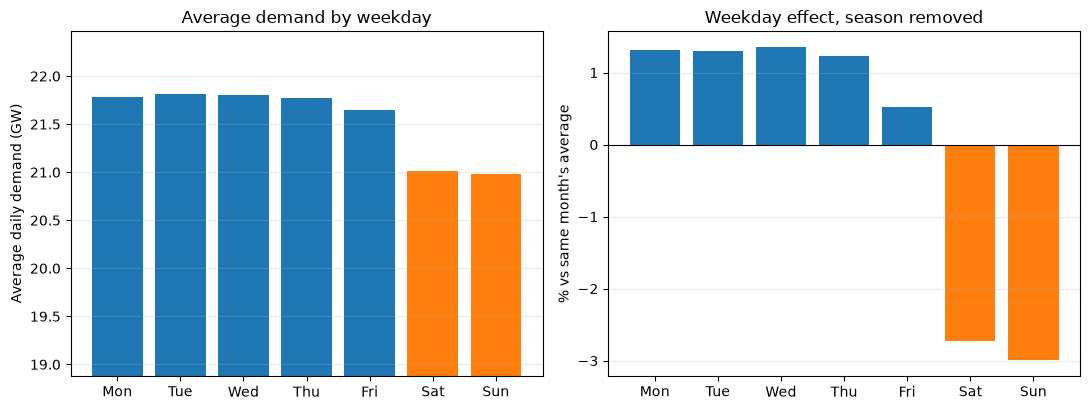

Mon    1.3
Tue    1.3
Wed    1.4
Thu    1.2
Fri    0.5
Sat   -2.7
Sun   -3.0
Name: gw, dtype: float64


In [3]:
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
d["dow"] = d.index.dayofweek
by_day = d.groupby("dow")["gw"].mean()
# compare at the same time of year, so winter vs summer doesn't hide the weekday effect
d["month"] = d.index.month
rel = (d["gw"] / d.groupby("month")["gw"].transform("mean") - 1) * 100
rel_day = rel.groupby(d["dow"]).mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(names, by_day.values, color=["C0"] * 5 + ["C1"] * 2)
axes[0].set_ylim(by_day.min() * 0.9, by_day.max() * 1.03)
axes[0].set_ylabel("Average daily demand (GW)")
axes[0].set_title("Average demand by weekday")
axes[1].bar(names, rel_day.values, color=["C0"] * 5 + ["C1"] * 2)
axes[1].axhline(0, color="black", lw=.8)
axes[1].set_ylabel("% vs same month's average")
axes[1].set_title("Weekday effect, season removed")
for ax in axes:
    ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(FIG / "eda_demand_by_weekday.png", dpi=150)
plt.show()
print(rel_day.round(1).set_axis(names))

### Demand by weekday

- **Weekday effect, season removed** (right panel): each day is compared with the average of its own month, so winter vs summer does not distort the comparison.
- Monday–Thursday run about **+1.3%** above a normal day for the season, Friday **+0.5%**, Saturday **−2.7%** and Sunday **−3.0%**. The weekday–weekend gap is about **4%**, roughly **0.9 GW** on an average day, as businesses and industry use less on weekends.
- A 4% weekly swing is several times the target forecast error (~1%), so the model needs calendar features (day of week, weekend flag).

In [4]:
import plotly.graph_objects as go

roll = d["gw"].rolling(30, center=True).mean()
peak = d["gw"].idxmax()

fig1 = go.Figure()
fig1.add_scatter(
    x=d.index, y=d["gw"], customdata=d["temp_mean"], mode="lines", name="Daily demand",
    line=dict(width=1, color="rgba(31,119,180,0.35)"),
    hovertemplate="%{x|%a %d %b %Y}<br><b>%{y:.1f} GW</b> at %{customdata:.1f} °C<extra></extra>")
fig1.add_scatter(
    x=roll.index, y=roll, mode="lines", name="30-day average",
    line=dict(width=2.5, color="black"),
    hovertemplate="30-day average: %{y:.1f} GW<extra></extra>")

fig1.add_vrect(x0="2020-03-23", x1="2020-05-31", fillcolor="red", opacity=0.12, line_width=0,
               annotation_text="COVID lockdown", annotation_position="top left")
fig1.add_annotation(x=peak, y=d.loc[peak, "gw"], showarrow=True, arrowhead=2, ax=-90, ay=0,
                    text=f"Cold snap {peak:%d %b %Y}<br>{d.loc[peak, 'gw']:.1f} GW",
                    bgcolor="white", bordercolor="grey")

fig1.update_layout(
    title="Québec electricity demand, 2019–2023",
    yaxis_title="Average daily demand (GW)",
    template="plotly_white", height=480, hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, x=1, xanchor="right"),
    xaxis=dict(
        rangeslider=dict(visible=True, thickness=0.08),
        rangeselector=dict(buttons=[
            dict(count=3, label="3 months", step="month", stepmode="backward"),
            dict(count=1, label="1 year", step="year", stepmode="backward"),
            dict(step="all", label="All"),
        ])))
fig1.write_html(FIG / "demand_over_time.html")
fig1.show()

In [6]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly = d.groupby([d.index.year, d.index.month])["gw"].mean().unstack(0)
avg5 = monthly.mean(axis=1)
years = list(monthly.columns)
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

fig2 = go.Figure()
for yr, col in zip(years, colors):
    diff = (monthly[yr] / avg5 - 1) * 100
    fig2.add_scatter(
        x=months, y=monthly[yr], customdata=diff, mode="lines+markers", name=str(yr),
        line=dict(color=col, width=2), marker=dict(color=col, size=7),
        hovertemplate=f"<b>{yr}</b> %{{x}}: %{{y:.1f}} GW<br>%{{customdata:+.1f}}% vs 5-year average"
                      "<extra></extra>")
fig2.add_scatter(x=months, y=avg5, mode="lines", name="5-year average",
                 line=dict(color="black", width=1.5, dash="dot"),
                 hovertemplate="5-year average %{x}: %{y:.1f} GW<extra></extra>")

def highlight(sel):
    """Colour the selected year, grey out the others (the average line stays black)."""
    c = [col if (sel is None or yr == sel) else "lightgrey" for yr, col in zip(years, colors)]
    w = [3.5 if yr == sel else (2 if sel is None else 1.2) for yr in years]
    return [{"line.color": c + ["black"], "marker.color": c + ["black"],
             "line.width": w + [1.5]}]

buttons = [dict(label="All years", method="restyle", args=highlight(None))]
buttons += [dict(label=str(yr), method="restyle", args=highlight(yr)) for yr in years]

fig2.update_layout(
    title="Same month, different years",
    yaxis_title="Monthly average demand (GW)",
    template="plotly_white", height=480, hovermode="closest",
    margin=dict(t=90, b=90),
    legend=dict(orientation="h", yanchor="top", y=-0.12, x=0.5, xanchor="center"),
    updatemenus=[dict(type="dropdown", buttons=buttons, x=1, xanchor="right",
                      y=1.12, yanchor="bottom", showactive=True)])
fig2.write_html(FIG / "demand_by_year.html")
fig2.show()

### Demand over time, 2019–2023

- **One dominant yearly cycle.** Demand peaks every winter (30-day average 28–33 GW) and bottoms out
  every summer (~16.5–18 GW): winter demand is close to **double** summer demand. This is the heating
  effect from plot 1 repeated every year.
- **Winters differ a lot from year to year, and the weather explains it.** January ranges from
  ~28 GW (2020, 2021, 2023: mild Januaries) to **32.4 GW in January 2022**, the coldest January in the
  data. November 2020 was the lowest November (21.9 GW), also a mild month. A forecast must therefore
  use the actual weather, not "same month last year".
- **A brief cold snap barely moves the monthly average.** February 2023 includes the highest day in
  the data (38.4 GW on 4 February) but its monthly average (29.5 GW) is ordinary. Extremes last a few
  days, which is why the model forecasts daily, not monthly.
- **Winter is far more volatile than summer.** Day-to-day swings reach several GW in winter (cold
  snaps, thaws) but stay within ~1–2 GW in summer. Forecast errors should be largest in winter, so the
  backtest reports results per quarter, not just one overall number.
- **The summer baseline is creeping up.** Summer months, which have little heating or cooling, rose
  from ~16.4–17.3 GW in 2019 to ~17.4–18.0 GW in 2022–2023, roughly **+1 GW (+6%)**. This points to
  structural growth (population, electrification, new industrial load). A model trained on older
  years would under-forecast, which supports an expanding training window and regular retraining.

In [7]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from pathlib import Path


ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
m = pd.read_parquet(ROOT / "data" / "processed" / "daily.parquet")
m = m.dropna(subset=["demand_mw", "temp_mean"]).copy()

# --- 1. a simple "normal behaviour" model, fitted on 2019 only (before COVID) ---
m["hdd15"] = np.clip(15 - m["temp_mean"], 0, None)   # heating need (base 15 °C, from plot 1)
m["cdd18"] = np.clip(m["temp_mean"] - 18, 0, None)   # cooling need
m["wkend"] = (m.index.dayofweek >= 5).astype(float)
cols = ["hdd15", "cdd18", "wkend"]

def X(df):
    return np.column_stack([np.ones(len(df)), df[cols].to_numpy()])

base = m.loc["2019"]
coef, *_ = np.linalg.lstsq(X(base), base["demand_mw"].to_numpy(), rcond=None)

# --- 2. what each day "should" have been, given its weather, and the gap ---
m["expected"] = X(m) @ coef
m["gap_pct"] = (m["demand_mw"] / m["expected"] - 1) * 100

print("2019 model: base %.0f MW | +%.0f MW per heating degree | +%.0f MW per cooling degree "
      "| weekend %+.0f MW" % tuple(coef))
fit_err = (m.loc["2019", "gap_pct"].abs()).mean()
print(f"Typical error of this simple model on 2019 itself: {fit_err:.1f}%")

# --- 3. the numbers you need ---
spring20 = m.loc["2020-04":"2020-05", "gap_pct"].mean()
spring19 = m.loc["2019-04":"2019-05", "gap_pct"].mean()
spring21 = m.loc["2021-04":"2021-05", "gap_pct"].mean()
print(f"\nApr–May gap vs weather-expected:  2019 {spring19:+.1f}%   "
      f"2020 {spring20:+.1f}%   2021 {spring21:+.1f}%")
print(f"COVID effect estimate (2020 minus avg of 2019 & 2021): "
      f"{spring20 - (spring19 + spring21) / 2:+.1f} percentage points")
print("\nAverage gap by year (%):")
print(m["gap_pct"].groupby(m.index.year).mean().round(1).to_string())
summer = m[m.index.month.isin([6, 7, 8])]
print("\nSummer (Jun–Aug) gap by year (%):")
print(summer["gap_pct"].groupby(summer.index.year).mean().round(1).to_string())

# --- 4. chart: monthly gap ---
gap_m = m["gap_pct"].resample("MS").mean()
fig = go.Figure(go.Bar(
    x=gap_m.index, y=gap_m.values,
    marker_color=np.where(gap_m.values < 0, "#d62728", "#1f77b4"),
    hovertemplate="%{x|%b %Y}: %{y:+.1f}% vs weather-expected<extra></extra>"))
fig.add_vrect(x0="2020-03-23", x1="2020-05-31", fillcolor="red", opacity=0.12, line_width=0,
              annotation_text="COVID lockdown", annotation_position="top left")
fig.add_hline(y=0, line_color="black", line_width=1)
fig.update_layout(title="Demand vs what 2019 behaviour + actual weather predicts",
                  yaxis_title="% vs weather-expected", template="plotly_white", height=400)
fig.write_html(FIG / "weather_adjusted_gap.html")
fig.show()

C:\Users\fatim\AppData\Local\Temp\ipykernel_29200\3288816829.py:15: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  m["wkend"] = (m.index.dayofweek >= 5).astype(float)


2019 model: base 16082 MW | +519 MW per heating degree | +303 MW per cooling degree | weekend -866 MW
Typical error of this simple model on 2019 itself: 3.3%

Apr–May gap vs weather-expected:  2019 -2.3%   2020 -5.2%   2021 +0.9%
COVID effect estimate (2020 minus avg of 2019 & 2021): -4.5 percentage points

Average gap by year (%):
date
2019    0.0
2020    0.1
2021    3.4
2022    5.7
2023    5.3

Summer (Jun–Aug) gap by year (%):
date
2019    1.1
2020    0.8
2021    6.0
2022    8.0
2023    6.5


### Demand over time, 2019–2023

**The yearly cycle**

- **One dominant yearly cycle.** Demand peaks every winter (30-day average 28–33 GW) and bottoms out
  every summer (~16.5–18 GW): winter demand is close to **double** summer demand, the heating effect
  from plot 1 repeated every year.
- **Winters differ a lot from year to year, and the weather explains it.** January ranges from
  ~28 GW (mild Januaries in 2020, 2021 and 2023) to **32.4 GW in January 2022**, the coldest January in
  the data. A forecast must use the actual weather, not "same month last year".
- **Short cold snaps barely move the monthly average.** February 2023 includes the highest day in the
  data (38.4 GW on 4 February) yet its monthly average (29.5 GW) is ordinary. Extremes last a few days,
  which is why the model forecasts daily.
- **Winter is far more volatile than summer.** Day-to-day swings reach several GW in winter but stay
  within ~1–2 GW in summer, so forecast errors should be largest in winter. The backtest therefore
  reports results per quarter, not one overall number.

**Removing the weather: a simple "2019 behaviour" model**

To separate weather from everything else, I fitted a simple linear model on 2019 only: demand =
base + heating degrees (base 15 °C) + cooling degrees (base 18 °C) + weekend. It gives
**+519 MW per heating degree**, **+303 MW per cooling degree** and **−866 MW on weekends**, consistent
with plots 1 and 2 (552 MW per degree below 10 °C; weekends ~4% lower). Its typical daily error on
2019 is **3.3%**. I then predicted every later day from its actual weather and measured the gap
between actual and expected demand.

- **COVID lowered demand by about 4.5% in spring 2020.** April–May 2020 came in 5.2% below what the
  weather predicts, against −2.3% in 2019 and +0.9% in 2021 for the same months. Net of the model's
  own seasonal bias, that is a **−4.5 point** COVID effect, with April 2020 the lowest month in the
  data (about −6%). Demand was back to normal by June 2020. The raw chart could not show this, because
  spring 2020 was also mild: only the weather-adjusted view separates the two.
- **Demand stepped up by ~5–6% from mid-2021 and stayed there.** The gap averages 0.0% in 2019 and
  0.1% in 2020, then +3.4% in 2021, **+5.7% in 2022** and **+5.3% in 2023**. The monthly chart shows
  a step around spring–summer 2021 rather than a gradual trend.
- **The extra load does not depend on the weather.** The step is larger in summer (+6% to +8%) than
  over the whole year (+3% to +6%). That is what a roughly constant extra load (about 1 GW, every day)
  looks like: the same MW is a bigger share of low summer demand than of high winter demand. Plausible
  causes are new industrial and commercial consumers, electrification and population growth; the data
  alone cannot say which.

**Implications for the model**

- **A model that learns old levels will under-forecast.** Trained on 2019–2020 only, it would be
  about 5% too low from 2021 on, five times the ~1% error targeted. This is the main risk in the data.
- **Lagged demand absorbs level shifts.** Lags (yesterday, last week) and rolling means already
  carry the new level, so the model adapts within days. This is a key reason to include them rather
  than rely on weather and calendar alone.
- **Training window and retraining matter.** The expanding-window backtest tests exactly this
  situation: its folds (mid-2022 to mid-2023) all come after the step. Worth testing in S3: training
  only from 2021 versus on all years, and the case for a regular retrain.
- **Use actual weather** (in production, the weather forecast), **expect larger winter errors**, and
  treat spring 2020 as unusual data.